In [1]:
import numpy as np              # numerical arrays and math
import pandas as pd             # data loading and manipulation
import matplotlib.pyplot as plt # plotting
import matplotlib.gridspec as gridspec  # multi-panel figure layouts
import scipy.signal as scipy_signal     # signal processing utilities
from scipy.fft import fft, fftfreq, ifft  # Fourier transforms
from scipy.stats import pearsonr, spearmanr, linregress  # statistics
import pywt                     # PyWavelets: all wavelet transforms
import warnings
warnings.filterwarnings('ignore')
import os

# Consistent plot appearance across all cells
plt.rcParams.update({
    'figure.dpi'        : 120,
    'axes.grid'         : True,
    'grid.alpha'        : 0.25,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'font.size'         : 10,
    'lines.linewidth'   : 1.5,
})

print("All imports successful.")

All imports successful.


In [2]:
saos_file_path = 'Data3_saos.xlsx'
laos_file_path = 'Data3_laos.xlsx'

In [3]:
saos_dataframe = pd.read_excel(saos_file_path, engine='openpyxl')

print("SAOS file loaded successfully.")
print(f"  Shape   : {saos_dataframe.shape[0]} rows x {saos_dataframe.shape[1]} columns")
print()
print("All columns:")
for column_name in saos_dataframe.columns:
    print(f"  {column_name}")
print()
print("First 5 rows:")
print(saos_dataframe.head())
print()
print("Basic statistics:")
print(saos_dataframe.describe())

SAOS file loaded successfully.
  Shape   : 16 rows x 21 columns

All columns:
  Storage modulus [Pa]
  Loss modulus [Pa]
  Tan(delta) []
  Angular frequency [rad/s]
  Oscillation torque [µN.m]
  Step time [s]
  Temperature [°C]
  Raw phase [°]
  Oscillation displacement [rad]
  Complex viscosity [Pa.s]
  Axial force [N]
  Oscillation stress [Pa]
  Time [s]
  Complex modulus [Pa]
  Frequency [Hz]
  Gap [µm]
  Oscillation strain []
  Oscillation strain rate [1/s]
  Phase angle [°]
  Step
  Source

First 5 rows:
   Storage modulus [Pa]  Loss modulus [Pa]  Tan(delta) []  \
0               28677.2            4622.99       0.161208   
1               34505.8            1066.81       0.030917   
2               37427.2            2798.36       0.074768   
3               37929.7            3841.95       0.101291   
4               37489.7            5444.96       0.145239   

   Angular frequency [rad/s]  Oscillation torque [µN.m]  Step time [s]  \
0                   100.0000                

Power law fit results:
  G' slope (n from storage modulus) : 0.687  (R = 0.872)
  G'' slope (n from loss modulus)   : -0.105  (R = -0.284)

Winter-Chambon interpretation:
  If G' slope ~ G'' slope, material is near gel point.
  tan(delta) at gel point = tan(n * pi/2) where n is the slope.

  tan(delta) range in data: 0.031 to 11.076
  Strongly varying tan(delta) = material NOT at gel point during sweep.
  This data was taken AFTER gelation was complete.


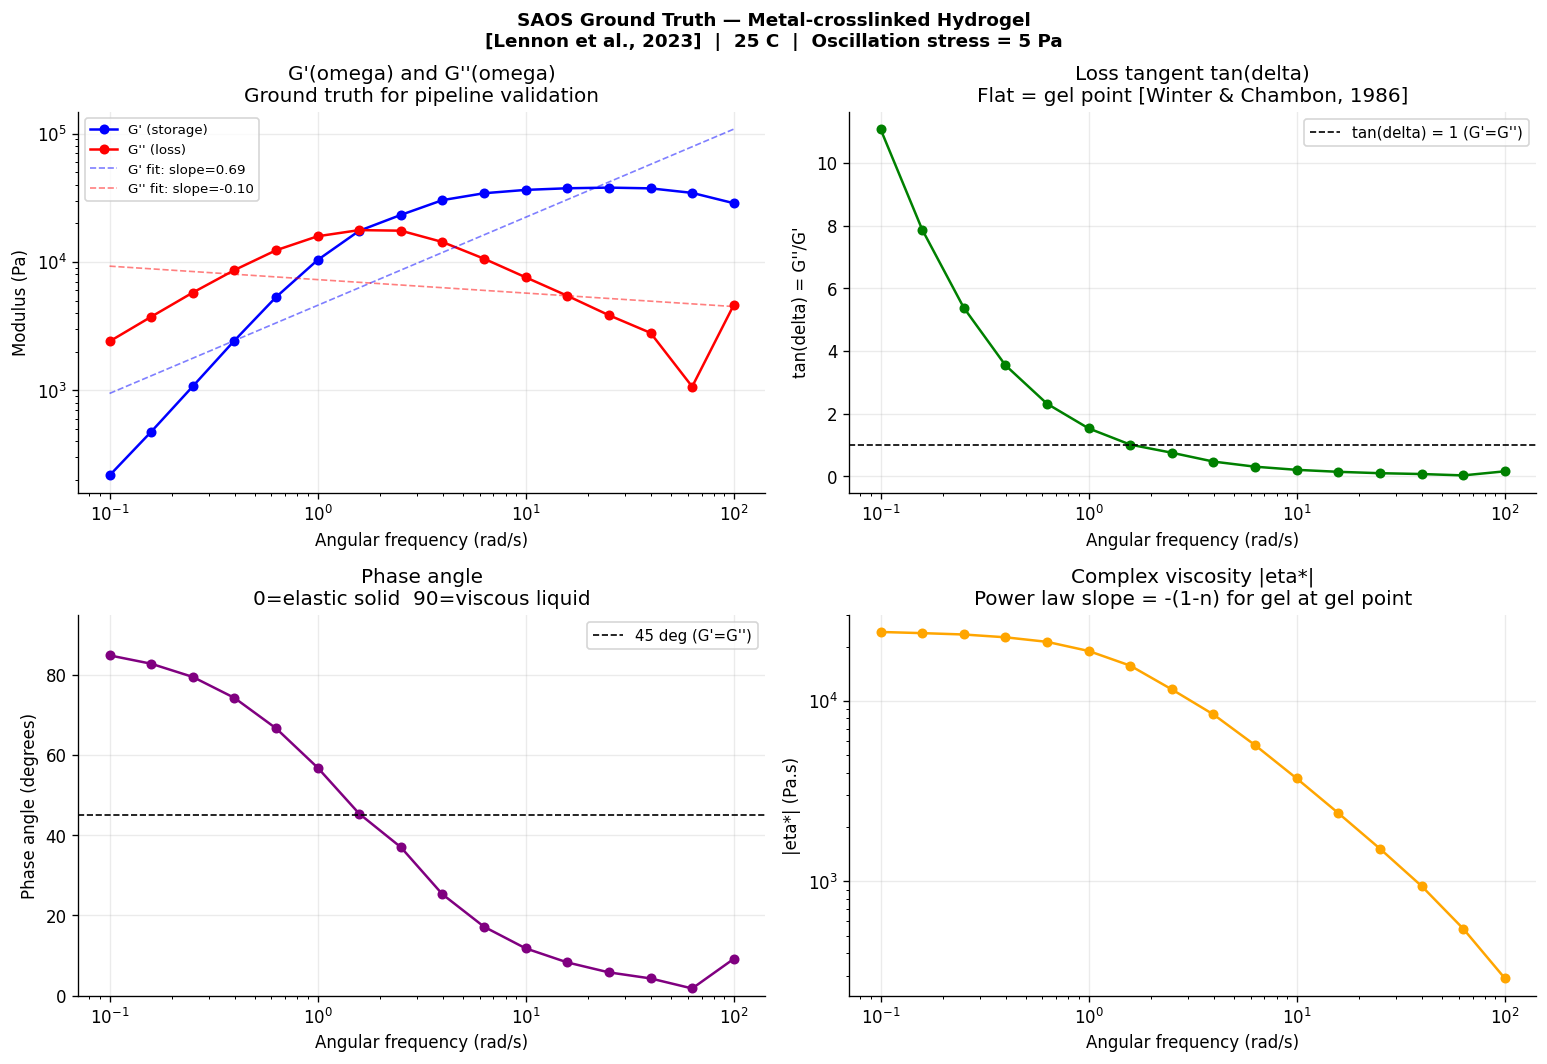

Figure saved: cell4_saos_ground_truth.png


In [4]:
# Extract the four columns we need as numpy arrays
saos_angular_frequency  = saos_dataframe['Angular frequency [rad/s]'].values
saos_storage_modulus    = saos_dataframe['Storage modulus [Pa]'].values
saos_loss_modulus       = saos_dataframe['Loss modulus [Pa]'].values
saos_tan_delta          = saos_dataframe['Tan(delta) []'].values
saos_phase_angle        = saos_dataframe['Phase angle [°]'].values
saos_complex_modulus    = saos_dataframe['Complex modulus [Pa]'].values
saos_complex_viscosity  = saos_dataframe['Complex viscosity [Pa.s]'].values

# Sort by frequency ascending so plots read left to right
sort_indices            = np.argsort(saos_angular_frequency)
saos_angular_frequency  = saos_angular_frequency[sort_indices]
saos_storage_modulus    = saos_storage_modulus[sort_indices]
saos_loss_modulus       = saos_loss_modulus[sort_indices]
saos_tan_delta          = saos_tan_delta[sort_indices]
saos_phase_angle        = saos_phase_angle[sort_indices]
saos_complex_modulus    = saos_complex_modulus[sort_indices]
saos_complex_viscosity  = saos_complex_viscosity[sort_indices]

# Compute the power law exponent n by fitting log(G') vs log(omega)
# At the gel point: G' ~ omega^n and G'' ~ omega^n. The slope on a log-log plot gives n directly
log_frequency           = np.log(saos_angular_frequency)
log_storage_modulus     = np.log(saos_storage_modulus)
log_loss_modulus        = np.log(saos_loss_modulus)

slope_storage, intercept_storage, r_storage, _, _ = linregress(
    log_frequency, log_storage_modulus)
slope_loss, intercept_loss, r_loss, _, _ = linregress(
    log_frequency, log_loss_modulus)

print("Power law fit results:")
print(f"  G' slope (n from storage modulus) : {slope_storage:.3f}  "
      f"(R = {r_storage:.3f})")
print(f"  G'' slope (n from loss modulus)   : {slope_loss:.3f}  "
      f"(R = {r_loss:.3f})")
print()
print("Winter-Chambon interpretation:")
print(f"  If G' slope ~ G'' slope, material is near gel point.")
print(f"  tan(delta) at gel point = tan(n * pi/2) where n is the slope.")
print()
print(f"  tan(delta) range in data: "
      f"{saos_tan_delta.min():.3f} to {saos_tan_delta.max():.3f}")
print(f"  Strongly varying tan(delta) = material NOT at gel point during sweep.")
print(f"  This data was taken AFTER gelation was complete.")

# Plot
figure, axes = plt.subplots(2, 2, figsize=(13, 9))
figure.suptitle(
    "SAOS Ground Truth — Metal-crosslinked Hydrogel\n"
    "[Lennon et al., 2023]  |  25 C  |  Oscillation stress = 5 Pa",
    fontsize=11, fontweight='bold')

# Panel 1: G' and G'' vs frequency (log-log)
# This is the standard rheology plot called a frequency sweep. The relative positions of G' and G'' tell us the gel state.
ax = axes[0, 0]
ax.loglog(saos_angular_frequency, saos_storage_modulus,
          'b-o', ms=5, label="G' (storage)")
ax.loglog(saos_angular_frequency, saos_loss_modulus,
          'r-o', ms=5, label="G'' (loss)")
ax.loglog(saos_angular_frequency,
          np.exp(intercept_storage) * saos_angular_frequency ** slope_storage,
          'b--', lw=1, alpha=0.5,
          label=f"G' fit: slope={slope_storage:.2f}")
ax.loglog(saos_angular_frequency,
          np.exp(intercept_loss) * saos_angular_frequency ** slope_loss,
          'r--', lw=1, alpha=0.5,
          label=f"G'' fit: slope={slope_loss:.2f}")
ax.set_xlabel('Angular frequency (rad/s)')
ax.set_ylabel('Modulus (Pa)')
ax.set_title("G'(omega) and G''(omega)\nGround truth for pipeline validation")
ax.legend(fontsize=8)

# Panel 2: tan(delta) vs frequency
# If this is flat (horizontal), the material is at the gel point. If it varies, the material is either clearly pre or post gel.
ax = axes[0, 1]
ax.semilogx(saos_angular_frequency, saos_tan_delta,
            'g-o', ms=5)
ax.axhline(1.0, color='k', ls='--', lw=1,
           label='tan(delta) = 1 (G\'=G\'\')')
ax.set_xlabel('Angular frequency (rad/s)')
ax.set_ylabel('tan(delta) = G\'\'/G\'')
ax.set_title("Loss tangent tan(delta)\n"
             "Flat = gel point [Winter & Chambon, 1986]")
ax.legend(fontsize=9)

# Panel 3: Phase angle vs frequency
# Same information as tan(delta) but expressed in degrees.
# At the gel point: phase angle = n * 90 degrees (constant).
# Phase angle = 0: purely elastic solid
# Phase angle = 90: purely viscous liquid
ax = axes[1, 0]
ax.semilogx(saos_angular_frequency, saos_phase_angle,
            'purple', marker='o', ms=5)
ax.axhline(45.0, color='k', ls='--', lw=1,
           label='45 deg (G\'=G\'\')')
ax.set_xlabel('Angular frequency (rad/s)')
ax.set_ylabel('Phase angle (degrees)')
ax.set_title("Phase angle\n0=elastic solid  90=viscous liquid")
ax.set_ylim([0, 95])
ax.legend(fontsize=9)

# Panel 4: Complex viscosity vs frequency (log-log)
# For a gel-like material this follows a power law: eta* ~ omega^(-n). The slope should be -(1-n) for a gel at the gel point.
# This is the Cox-Merz rule application.
ax = axes[1, 1]
ax.loglog(saos_angular_frequency, saos_complex_viscosity,
          'orange', marker='o', ms=5)
ax.set_xlabel('Angular frequency (rad/s)')
ax.set_ylabel('|eta*| (Pa.s)')
ax.set_title("Complex viscosity |eta*|\n"
             "Power law slope = -(1-n) for gel at gel point")

plt.tight_layout()
plt.savefig('cell4_saos_ground_truth.png', dpi=120, bbox_inches='tight')
plt.show()
print("Figure saved: cell4_saos_ground_truth.png")

In [5]:
# We extract just ONE number from SAOS: G' and G'' at omega = 1 rad/s.
# This is the drive frequency of the LAOS experiment, so it gives us a ground truth reference to validate our pipeline outputs against.

# Then we load the raw LAOS time series and print basic info.

# ── Extract SAOS reference at omega = 1 rad/s ─────────────────────────────────
# Find the index of the frequency point closest to 1 rad/s
reference_frequency_rad_per_s  = 1.0
reference_frequency_index      = np.argmin(np.abs(saos_angular_frequency - reference_frequency_rad_per_s))
saos_reference_frequency       = saos_angular_frequency[reference_frequency_index]
saos_reference_storage_modulus = saos_storage_modulus[reference_frequency_index]
saos_reference_loss_modulus    = saos_loss_modulus[reference_frequency_index]
saos_reference_tan_delta       = saos_reference_loss_modulus / saos_reference_storage_modulus

print("── SAOS Reference Point (ground truth for pipeline validation) ─────────")
print(f"  Closest frequency found : {saos_reference_frequency:.4f} rad/s")
print(f"  G' (storage modulus)    : {saos_reference_storage_modulus:.2f} Pa")
print(f"  G'' (loss modulus)      : {saos_reference_loss_modulus:.2f} Pa")
print(f"  tan(delta)              : {saos_reference_tan_delta:.4f}")
print()
print("  Any method that recovers G' and G'' from the LAOS time series")
print("  should match these values in the low-amplitude (linear) regime.")
print()

# ── Load LAOS data ─────────────────────────────────────────────────────────────
laos_file_path  = 'Data3_laos.xlsx'
laos_dataframe  = pd.read_excel(laos_file_path, sheet_name=0, header=0)
laos_dataframe.columns = laos_dataframe.columns.str.strip()

print("── LAOS Data Overview ──────────────────────────────────────────────────")
print(f"  Shape  : {laos_dataframe.shape[0]} rows x {laos_dataframe.shape[1]} columns")
print()
print("  Columns:")
for column_name in laos_dataframe.columns:
    print(f"    {column_name}")
print()
print(laos_dataframe.head())

── SAOS Reference Point (ground truth for pipeline validation) ─────────
  Closest frequency found : 1.0000 rad/s
  G' (storage modulus)    : 10352.30 Pa
  G'' (loss modulus)      : 15846.30 Pa
  tan(delta)              : 1.5307

  Any method that recovers G' and G'' from the LAOS time series
  should match these values in the low-amplitude (linear) regime.

── LAOS Data Overview ──────────────────────────────────────────────────
  Shape  : 61324 rows x 13 columns

  Columns:
    Displacement [rad]
    Gap [µm]
    Normal stress [Pa]
    Step time [s]
    Strain []
    Stress [Pa]
    Temperature [°C]
    Time [s]
    Torque [µN.m]
    Compliance [1/Pa]
    Strain (step) []
    Step
    Source

   Displacement [rad]  Gap [µm]  Normal stress [Pa]  Step time [s]  \
0       -3.331790e-07   700.004             314.492       0.000000   
1       -3.756040e-07   700.004             266.529       0.002048   
2       -4.224170e-07   700.004             166.960       0.004096   
3       -3.55489

In [6]:
# ── Extract the four key arrays ───────────────────────────────────────────────
laos_time_array   = laos_dataframe['Time [s]'].values.astype(float)
laos_strain_array = laos_dataframe['Strain []'].values.astype(float)
laos_stress_array = laos_dataframe['Stress [Pa]'].values.astype(float)
laos_step_labels  = laos_dataframe['Step'].values

# ── Infer sampling rate ───────────────────────────────────────────────────────
time_differences          = np.diff(laos_time_array)
positive_time_differences = time_differences[time_differences > 0]
median_time_step          = np.median(positive_time_differences)
sampling_rate_hz          = 1.0 / median_time_step

print(f"Sampling rate : {sampling_rate_hz:.2f} Hz")
print(f"Time step     : {median_time_step*1000:.4f} ms")
print()

# ── Check strain magnitude ────────────────────────────────────────────────────
print("── Strain Sanity Check ─────────────────────────────────────────────────")
print(f"  Strain [] min : {laos_strain_array.min():.6e}")
print(f"  Strain [] max : {laos_strain_array.max():.6e}")
print(f"  Stress [Pa] min : {laos_stress_array.min():.4f}")
print(f"  Stress [Pa] max : {laos_stress_array.max():.4f}")
print(f"  Naive G* estimate (stress_max / strain_max) : "
      f"{laos_stress_array.max() / (np.max(np.abs(laos_strain_array)) + 1e-30):.2f} Pa")
print(f"  SAOS reference G* at 1 rad/s : "
      f"{np.sqrt(saos_reference_storage_modulus**2 + saos_reference_loss_modulus**2):.2f} Pa")
print()

# ── Segment by step ───────────────────────────────────────────────────────────
unique_step_labels = pd.Series(laos_step_labels).unique()
print(f"Unique steps found: {unique_step_labels}")
print()

laos_segments = {}
for step_label in unique_step_labels:
    step_mask = laos_step_labels == step_label
    step_time_array   = laos_time_array[step_mask]
    step_stress_array = laos_stress_array[step_mask]
    step_strain_array = laos_strain_array[step_mask]
    step_duration     = step_time_array[-1] - step_time_array[0]
    step_stress_rms   = np.sqrt(np.mean(step_stress_array**2))

    laos_segments[step_label] = {
        'time_array'   : step_time_array,
        'stress_array' : step_stress_array,
        'strain_array' : step_strain_array,
        'n_samples'    : int(np.sum(step_mask)),
        'duration_s'   : step_duration,
        'stress_rms_pa': step_stress_rms,
    }

    print(f"  Step: {step_label}")
    print(f"    Samples    : {int(np.sum(step_mask))}")
    print(f"    Duration   : {step_duration:.2f} s")
    print(f"    RMS stress : {step_stress_rms:.2f} Pa")
    print(f"    Peak stress: {np.max(np.abs(step_stress_array)):.2f} Pa")
    print()

Sampling rate : 500.00 Hz
Time step     : 2.0000 ms

── Strain Sanity Check ─────────────────────────────────────────────────
  Strain [] min : -3.518990e-01
  Strain [] max : 9.858940e-01
  Stress [Pa] min : -3999.7600
  Stress [Pa] max : 3999.9100
  Naive G* estimate (stress_max / strain_max) : 4057.14 Pa
  SAOS reference G* at 1 rad/s : 18928.16 Pa

Unique steps found: <StringArray>
['gel_1rads_1', 'gel_1rads_2', 'gel_1rads_3', 'gel_1rads_4']
Length: 4, dtype: str

  Step: gel_1rads_1
    Samples    : 15331
    Duration   : 31.40 s
    RMS stress : 707.24 Pa
    Peak stress: 999.97 Pa

  Step: gel_1rads_2
    Samples    : 15331
    Duration   : 31.40 s
    RMS stress : 1414.49 Pa
    Peak stress: 1999.95 Pa

  Step: gel_1rads_3
    Samples    : 15331
    Duration   : 31.40 s
    RMS stress : 2828.98 Pa
    Peak stress: 3999.91 Pa

  Step: gel_1rads_4
    Samples    : 15331
    Duration   : 31.40 s
    RMS stress : 2121.73 Pa
    Peak stress: 2999.94 Pa

